Original image shape: torch.Size([600, 1, 16, 16])
Flattened input shape: torch.Size([600, 256])
Initial score shape: torch.Size([4, 3])
Initial scores:
 tensor([[-0.0263,  0.0542, -0.2271],
        [ 0.1762,  0.2035, -0.1745],
        [ 0.0533, -0.1798,  0.3562],
        [-0.1937, -0.2563, -0.1131]])
True labels: [1, 2, 2, 0]
epoch=  0 | loss=1.0936 | train accuracy=0.500
epoch= 20 | loss=0.0339 | train accuracy=1.000
epoch= 40 | loss=0.0170 | train accuracy=1.000
epoch= 60 | loss=0.0113 | train accuracy=1.000
epoch= 80 | loss=0.0085 | train accuracy=1.000
epoch=100 | loss=0.0068 | train accuracy=1.000

Test score shape: torch.Size([150, 3])
Test accuracy: 1.000
Weight matrix shape: torch.Size([3, 256])


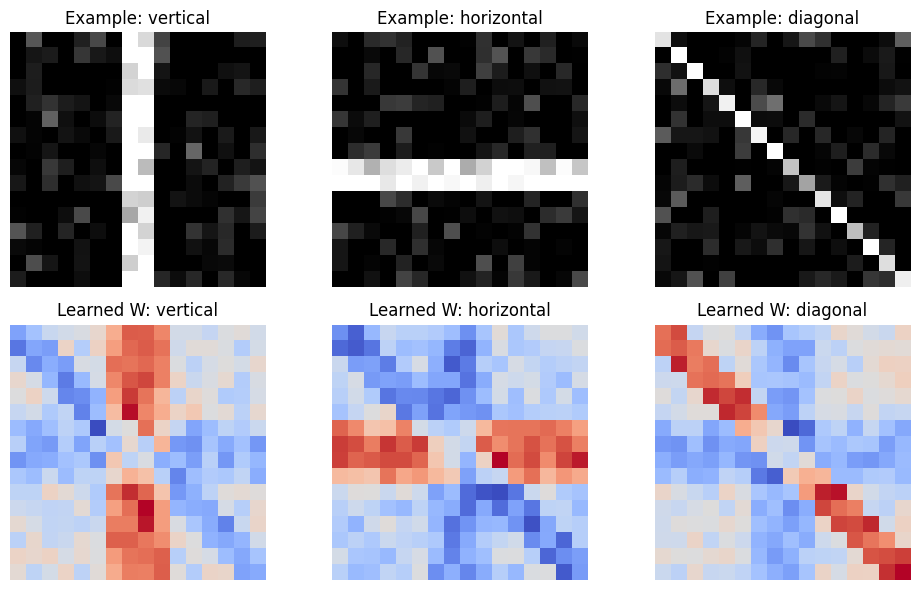

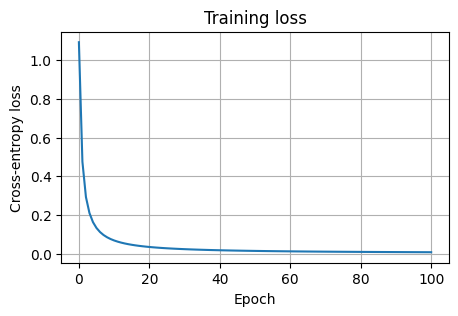

In [2]:
### CS231n_Lec02_review_Linear_Classifier

import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

IMAGE_SIZE = 16
NUM_CLASSES = 3
CLASS_NAMES = ("vertical", "horizontal", "diagonal")


## Generate three types of line images and meaningful ground-truth labels
def make_dataset(num_samples):

    # images.shape = (N, C, H, W)
    images = torch.zeros(num_samples, 1, IMAGE_SIZE, IMAGE_SIZE)
    labels = torch.randint(0, NUM_CLASSES, (num_samples,))

    for i in range(num_samples):
        label = labels[i].item()
        shift = torch.randint(-1, 2, ()).item()

        if label == 0:
            # vertical line near the center with randomly shifted
            column = IMAGE_SIZE // 2 + shift
            images[i, 0, :, column - 1:column + 1] = 1.0

        elif label == 1:
            # horizontal line near the center with randomly shifted
            row = IMAGE_SIZE // 2 + shift
            images[i, 0, row - 1:row + 1, :] = 1.0

        else:
            # diagonal with slightly shifted
            for row in range(IMAGE_SIZE):
                column = row + shift

                if 0 <= column < IMAGE_SIZE:
                    images[i, 0, row, column] = 1.0

        # Add tiny pixel noises like signal noises
        images[i] += 0.15 * torch.randn_like(images[i])
        images[i].clamp_(0.0, 1.0)

    return images, labels


## Create the train and test datasets.
train_images, train_labels = make_dataset(600)
test_images, test_labels = make_dataset(150)

print("Original image shape:", train_images.shape)


## Flatten each image to a vector of length 256
train_x = train_images.flatten(start_dim=1)
test_x = test_images.flatten(start_dim=1)

print("Flattened input shape:", train_x.shape)


## Implement a simple linear classifier model
class LinearImageClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        # 16×16(IMAGE_SIZE) input features → 3 class scores
        self.linear = nn.Linear(
            IMAGE_SIZE * IMAGE_SIZE,
            NUM_CLASSES
        )

    def forward(self, x):
        scores = self.linear(x)
        return scores

model = LinearImageClassifier()

## Compute and initialize the starting scores without tracking gradients (saves
# memory)
with torch.no_grad():
    initial_scores = model(test_x[:4])

print("Initial score shape:", initial_scores.shape)
print("Initial scores:\n", initial_scores)
print("True labels:", test_labels[:4].tolist())


## Set the criterion(loss function) and optimizer(SGD)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.5)

loss_history = []


## Train for 100 epochs
for epoch in range(101):
    scores = model(train_x)
    loss = criterion(scores, train_labels)

    optimizer.zero_grad() # Initialize gradients from the previous loop
    loss.backward() # Calculate the gradient of each parameter through backpropagation
    optimizer.step() # Update parameters (weights) using the calculated gradients.

    loss_history.append(loss.item())

    # check the predictions and accuracy per 20 epochs
    if epoch % 20 == 0:
        predictions = scores.argmax(dim=1) # define the prediction as label with the highest scores
        accuracy = (predictions == train_labels).float().mean()

        print(
            f"epoch={epoch:3d} | "
            f"loss={loss.item():.4f} | "
            f"train accuracy={accuracy.item():.3f}"
        )


## Compute the test scores without tracking gradients (saves memory)
with torch.no_grad():
    test_scores = model(test_x)
    test_predictions = test_scores.argmax(dim=1)
    test_accuracy = (
        test_predictions == test_labels
    ).float().mean()

print("\nTest score shape:", test_scores.shape)
print(f"Test accuracy: {test_accuracy.item():.3f}")


## Weight shape of the linear layer:
# (Number of classes, Number of input features) = (3, 256)
weights = model.linear.weight.detach()
print("Weight matrix shape:", weights.shape)

weight_images = weights.reshape(
    NUM_CLASSES, IMAGE_SIZE, IMAGE_SIZE
)


## visualize the predicted result samples & learned weights matrix
# by Linear Classifier for each target.
fig, axes = plt.subplots(2, 3, figsize=(10, 6))

for class_index in range(NUM_CLASSES):
    sample_index = (
        test_labels == class_index
    ).nonzero()[0].item()

    axes[0, class_index].imshow(
        test_images[sample_index, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[0, class_index].set_title(
        f"Example: {CLASS_NAMES[class_index]}"
    )

    axes[1, class_index].imshow(
        weight_images[class_index],
        cmap="coolwarm"
    )
    axes[1, class_index].set_title(
        f"Learned W: {CLASS_NAMES[class_index]}"
    )

    axes[0, class_index].axis("off")
    axes[1, class_index].axis("off")

plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 3))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Training loss")
plt.grid(True)
plt.show()